# 04 — Guo-inspired bicycle-type speed sensitivity and matched-OD comparison

**Paper 3 · Toronto Bike Share June 2024 · Behavioural baseline, NO pollution exposure yet**

**Questions:** (1) How sensitive is recorded-minus-modelled trip time to assumed routing speed? (2) How much of the apparent electric/conventional gap remains for repeated trips between the **same directed station pair**? (3) What is robust across modelling scenarios?

**Interpretation:** GraphHopper used one `bike` model for both classes. The counterfactual values here rescale its **travel-time estimate** by a multiplicative factor; they **do not reroute** trips, calibrate true speeds, or demonstrate causal effects. Rental duration includes non-riding time. OD matching cannot control rider selection, weather, traffic, or trip purpose. Road and station snapshots are retrospective/provisional.

In [1]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('/scratch/project_2010417/paper3/toronto-bike-exposure')
DATA = ROOT / 'data/processed'
OUT = ROOT / 'outputs/guo_bike_type_speed_sensitivity'
OUT.mkdir(parents=True, exist_ok=True)
TRIPS = DATA / 'bikeshare_june_2024_validated.parquet'
ROUTES = DATA / 'full_june_routes.sqlite'
assert TRIPS.exists(), f'Missing: {TRIPS}'
assert ROUTES.exists(), f'Missing: {ROUTES}'
print('Outputs:', OUT)


Outputs: /scratch/project_2010417/paper3/toronto-bike-exposure/outputs/guo_bike_type_speed_sensitivity


## 1 — Load trips and reconstruct the original baseline join

The code matches the earlier `03_guo_2026_travel_time_baseline.ipynb` rules: positive duration, distinct stations, valid departure timestamp, and successful directed GraphHopper routes. `Trip_Duration` is treated as **seconds**. The analysis uses no geometry to reduce memory.

In [2]:
def norm_id(s):
    return s.astype('string').str.strip().str.replace(r'\.0+$', '', regex=True)

t = pd.read_parquet(TRIPS, columns=['Start_Station_Id','End_Station_Id','Trip_Duration','Start_Time','Bike_Model'])
t['Start_Station_Id'] = norm_id(t['Start_Station_Id'])
t['End_Station_Id'] = norm_id(t['End_Station_Id'])
t['duration_s'] = pd.to_numeric(t['Trip_Duration'], errors='coerce')
t['started_at'] = pd.to_datetime(t['Start_Time'], errors='coerce')
keep = (t.duration_s.gt(0) & t.Start_Station_Id.notna() & t.End_Station_Id.notna()
        & t.Start_Station_Id.ne(t.End_Station_Id) & t.started_at.notna()).fillna(False)
t = t.loc[keep].copy()

with sqlite3.connect(ROUTES) as db:
    r = pd.read_sql_query("SELECT start_id,end_id,distance_m,time_min FROM routes WHERE geometry_json IS NOT NULL AND error IS NULL", db)
r['start_id'] = norm_id(r['start_id']); r['end_id'] = norm_id(r['end_id'])
assert not r.duplicated(['start_id','end_id']).any(), 'Duplicate routes'
r['time_min'] = pd.to_numeric(r.time_min,errors='coerce')
r['distance_m'] = pd.to_numeric(r.distance_m,errors='coerce')
r = r.loc[r.time_min.gt(0) & r.distance_m.gt(0)]

df = t.merge(r, left_on=['Start_Station_Id','End_Station_Id'],
             right_on=['start_id','end_id'],how='inner',validate='many_to_one')
model = df.Bike_Model.astype('string').str.upper().str.strip()
df['bike_type'] = np.select([model.str.startswith('EFIT',na=False),model.eq('ICONIC').fillna(False)],
                            ['Electric','Conventional'],default='Unknown')
df = df.loc[df.bike_type.isin(['Electric','Conventional'])].copy()
df['observed_min'] = df.duration_s/60
# Same transparent quality restrictions as notebook 03
before = len(df)
df = df.loc[df.observed_min.between(1,90) & df.time_min.between(.5,90)
            & df.distance_m.ge(100)].copy()
df['delta_baseline'] = df.observed_min - df.time_min
print(f'Quality-filtered known-bike trips: {len(df):,} / {before:,}')
print(df.bike_type.value_counts().to_string())
print('Original model time median (minutes):', round(df.time_min.median(),2))


Quality-filtered known-bike trips: 730,853 / 737,915
bike_type
Conventional    603250
Electric        127603
Original model time median (minutes): 8.07


## 2 — Baseline speed sensitivity

For each bicycle type, multiply the implied baseline model speed by a **scenario factor**. If `f = 1.20`, predicted route time becomes `baseline_time / 1.20`. These are illustrative model sensitivities, **not measured bicycle speeds**. Keep the conventional reference factor 1.00 while varying the electric factor, then test both together as a wider robustness check.

In [3]:
ELECTRIC_FACTORS = [0.90, 1.00, 1.10, 1.20, 1.30, 1.40, 1.50]
scenarios = []
for f in ELECTRIC_FACTORS:
    adjusted_time = np.where(df.bike_type.eq('Electric'), df.time_min / f, df.time_min)
    delta = df.observed_min.to_numpy() - adjusted_time
    for bt in ['Conventional','Electric']:
        mask = df.bike_type.eq(bt).to_numpy()
        v = delta[mask]
        scenarios.append({'electric_speed_factor':f,'bike_type':bt,'n':len(v),
                          'median_delta_min':np.median(v),'mean_delta_min':np.mean(v),
                          'share_negative':np.mean(v<0), 'p10':np.quantile(v,.1), 'p90':np.quantile(v,.9)})
scenario_summary = pd.DataFrame(scenarios)
print(scenario_summary.round(3).to_string(index=False))
scenario_summary.to_csv(OUT/'speed_factor_scenarios.csv',index=False)


 electric_speed_factor    bike_type      n  median_delta_min  mean_delta_min  share_negative    p10    p90
                   0.9 Conventional 603250             3.053           5.619           0.106 -0.056 13.000
                   0.9     Electric 127603             0.518           2.890           0.423 -2.823  9.658
                   1.0 Conventional 603250             3.053           5.619           0.106 -0.056 13.000
                   1.0     Electric 127603             1.550           4.142           0.271 -1.416 11.165
                   1.1 Conventional 603250             3.053           5.619           0.106 -0.056 13.000
                   1.1     Electric 127603             2.464           5.166           0.153 -0.459 12.490
                   1.2 Conventional 603250             3.053           5.619           0.106 -0.056 13.000
                   1.2     Electric 127603             3.265           6.019           0.080  0.190 13.635
                   1.3 Conventional 6

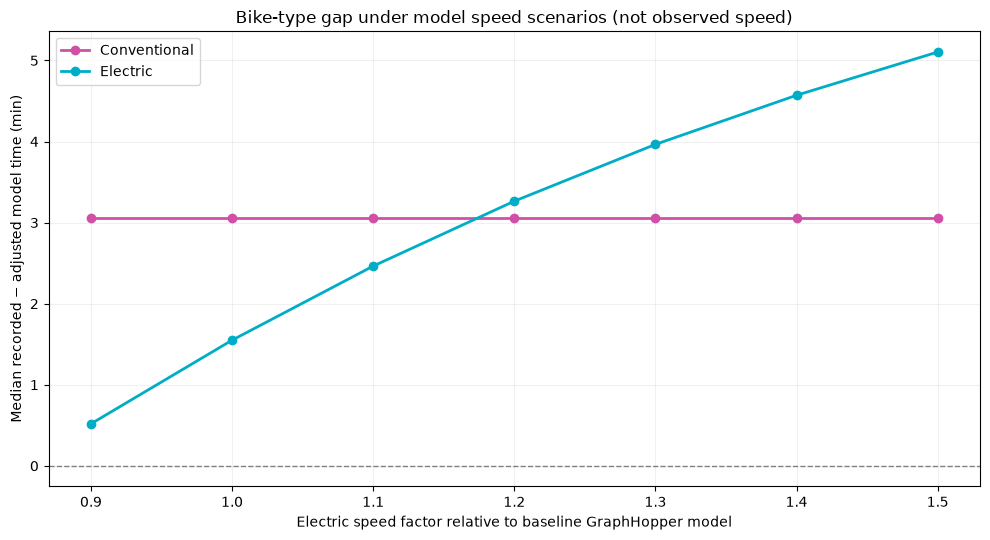

In [4]:
fig,ax=plt.subplots(figsize=(10,5.5))
for bt,color in [('Conventional','#d24fa8'),('Electric','#00adc6')]:
    z=scenario_summary.query('bike_type == @bt')
    ax.plot(z.electric_speed_factor,z.median_delta_min,marker='o',color=color,lw=2,label=bt)
ax.axhline(0,ls='--',color='gray',lw=1)
ax.set(xlabel='Electric speed factor relative to baseline GraphHopper model',
       ylabel='Median recorded − adjusted model time (min)',
       title='Bike-type gap under model speed scenarios (not observed speed)')
ax.legend();ax.grid(alpha=.18);fig.tight_layout()
fig.savefig(OUT/'01_speed_sensitivity_median.png',dpi=200);plt.show();plt.close(fig)


## 3 — Matched origin–destination comparison

Use only directed OD pairs with **at least 5 conventional and 5 electric trips**. Compute within-OD median recorded time for each type, and their difference (`Electric − Conventional`). Same OD means the baseline GraphHopper time cancels **at factor 1.0**, avoiding misleading comparisons due solely to different OD composition. This is still **descriptive**, not causal, and within-OD differences can reflect user selection and other factors.

In [5]:
keys=['Start_Station_Id','End_Station_Id']
agg=(df.groupby(keys+['bike_type'],observed=True)
       .agg(n=('observed_min','size'),median_observed=('observed_min','median'),
            median_model=('time_min','median'),median_delta=('delta_baseline','median'),
            distance_m=('distance_m','median')).reset_index())
wide=agg.pivot(index=keys,columns='bike_type',values=['n','median_observed','median_model','median_delta','distance_m'])
wide.columns=[f'{metric}_{kind}' for metric,kind in wide.columns]
wide=wide.reset_index()
MIN_PER_TYPE=5
paired=wide.loc[(wide['n_Conventional']>=MIN_PER_TYPE)&(wide['n_Electric']>=MIN_PER_TYPE)].copy()
paired['observed_gap_electric_minus_conventional'] = (paired.median_observed_Electric-paired.median_observed_Conventional)
paired['delta_gap_electric_minus_conventional'] = (paired.median_delta_Electric-paired.median_delta_Conventional)
paired['paired_weight'] = np.minimum(paired.n_Electric,paired.n_Conventional)
print(f'Directed ODs with >= {MIN_PER_TYPE} trips per bike type: {len(paired):,}')
print('Median within-OD observed duration gap (Electric−Conventional):',
      round(paired.observed_gap_electric_minus_conventional.median(),3),'min')
print('Median within-OD baseline delta gap:',
      round(paired.delta_gap_electric_minus_conventional.median(),3),'min')
print('Fraction of matched ODs where electric median is shorter:',
      round((paired.observed_gap_electric_minus_conventional<0).mean(),3))
paired.to_csv(OUT/'paired_directed_od_summary.csv',index=False)


Directed ODs with >= 5 trips per bike type: 2,362
Median within-OD observed duration gap (Electric−Conventional): -0.933 min
Median within-OD baseline delta gap: -0.933 min
Fraction of matched ODs where electric median is shorter: 0.773


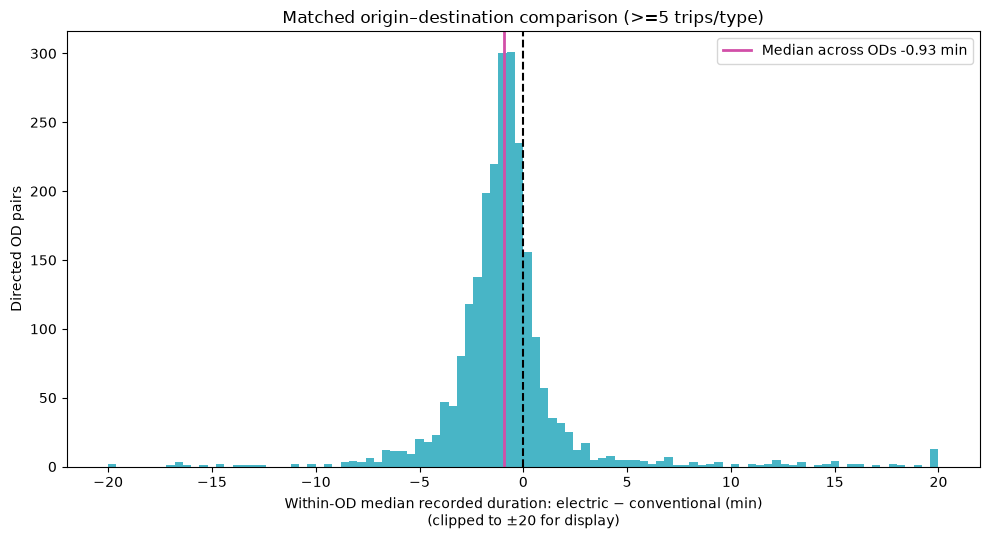

In [6]:
fig,ax=plt.subplots(figsize=(10,5.5))
values=paired['observed_gap_electric_minus_conventional'].dropna()
ax.hist(values.clip(-20,20),bins=np.linspace(-20,20,101),color='#28a8bc',alpha=.85)
ax.axvline(0,color='black',ls='--')
if len(values): ax.axvline(values.median(),color='#d24fa8',lw=2,label=f'Median across ODs {values.median():+.2f} min')
ax.set(xlabel='Within-OD median recorded duration: electric − conventional (min)\n(clipped to ±20 for display)',
       ylabel='Directed OD pairs',title='Matched origin–destination comparison (>=5 trips/type)')
ax.legend();fig.tight_layout();fig.savefig(OUT/'02_matched_od_observed_gap.png',dpi=200);plt.show();plt.close(fig)


## 4 — Compare within-OD *adjusted model residuals* by scenario

Rescaling model time for electric trips also changes the residual gap. Here we do it from aggregated OD medians, exploiting that a single OD pair has the same graph-based route time for both bicycle classes. The paired-OD sample stays fixed across scenarios.

 electric_speed_factor  paired_od_count  median_paired_residual_gap_min  share_od_electric_lower
                   0.9             2362                          -1.598                    0.860
                   1.0             2362                          -0.933                    0.773
                   1.1             2362                          -0.397                    0.643
                   1.2             2362                           0.043                    0.480
                   1.3             2362                           0.437                    0.355
                   1.4             2362                           0.769                    0.259
                   1.5             2362                           1.040                    0.188


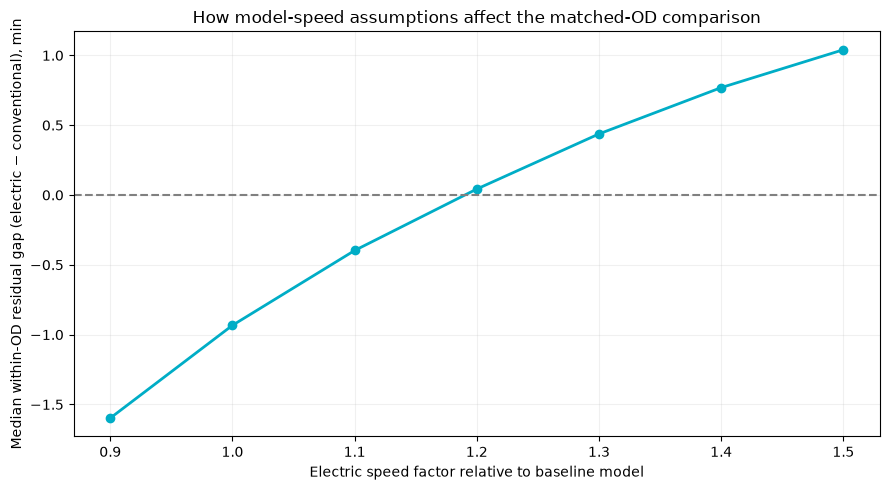

In [7]:
rows=[]
for f in ELECTRIC_FACTORS:
    # Since baseline routing times are identical per OD, only the electric residual changes
    gap=(paired.median_observed_Electric - paired.median_model_Electric/f
         - (paired.median_observed_Conventional-paired.median_model_Conventional))
    rows.append({'electric_speed_factor':f,'paired_od_count':len(gap),
                 'median_paired_residual_gap_min':gap.median(),
                 'share_od_electric_lower':(gap<0).mean()})
paired_scenarios=pd.DataFrame(rows)
print(paired_scenarios.round(3).to_string(index=False))
paired_scenarios.to_csv(OUT/'matched_od_scenario_summary.csv',index=False)
fig,ax=plt.subplots(figsize=(9,5))
ax.plot(paired_scenarios.electric_speed_factor,paired_scenarios.median_paired_residual_gap_min,
        marker='o',color='#00adc6',lw=2)
ax.axhline(0,color='gray',ls='--')
ax.set(xlabel='Electric speed factor relative to baseline model',
       ylabel='Median within-OD residual gap (electric − conventional), min',
       title='How model-speed assumptions affect the matched-OD comparison')
ax.grid(alpha=.18);fig.tight_layout();fig.savefig(OUT/'03_matched_od_speed_sensitivity.png',dpi=200);plt.show();plt.close(fig)


## 5 — Robustness: distance strata and weekday/weekend

These descriptive stratifications help distinguish a consistent association from differences in trip length and day-of-week composition; they do **not** identify causal mechanisms.

In [8]:
df['distance_band_km']=pd.cut(df.distance_m/1000,bins=[.1,1,2,4,8,100],
                                 labels=['0.1–1','1–2','2–4','4–8','8+'],right=False)
df['weekend']=df.started_at.dt.dayofweek.ge(5)
strata=(df.groupby(['distance_band_km','weekend','bike_type'],observed=True)
          .agg(n=('observed_min','size'),median_observed=('observed_min','median'),
               median_baseline_delta=('delta_baseline','median')).reset_index())
print(strata.to_string(index=False))
strata.to_csv(OUT/'distance_weekend_strata.csv',index=False)


distance_band_km  weekend    bike_type      n  median_observed  median_baseline_delta
           0.1–1    False Conventional  59175         4.250000               1.190350
           0.1–1    False     Electric   8434         4.000000               0.884350
           0.1–1     True Conventional  25949         4.600000               1.525000
           0.1–1     True     Electric   3492         4.416667               1.298975
             1–2    False Conventional 133540         7.733333               2.063433
             1–2    False     Electric  22676         6.816667               1.057567
             1–2     True Conventional  54987         8.266667               2.564500
             1–2     True     Electric   8778         7.183333               1.447842
             2–4    False Conventional 160951        13.600000               3.581017
             2–4    False     Electric  35096        11.816667               1.563433
             2–4     True Conventional  66319        1

## 6 — Summary and limitations for Paper 3

1. Distinguish **model-implied time residuals** from directly observed cycling speeds; `Trip_Duration` can include dwell and docking.
2. Higher assumed electric speeds can reduce negative residuals; a factor sweep **does not calibrate** the actual electric routing model.
3. Within-OD median *recorded time* comparison removes OD routing-time composition at baseline, but still reflects rider type, timing, and route-selection differences.
4. June 2024 station locations are provisional; route graph uses a later OSM snapshot. Confirm extreme/near-zero OD routes separately.
5. Next: validate with external travel-speed data or a bicycle-type-specific routing model, and assess uncertainty before defining any avoidable-exposure indicator.

**Files written** to `outputs/guo_bike_type_speed_sensitivity/`. They are ignored by Git in the research repository.